# k по периодам, ADF, наивный прогноз, трейн/тест и скользящие окна

Что проверяем и где это в ноутбуке:

| Задание | Раздел |
|---|---|
| Диаграмма рассеяния цены карбамида против TTF с линией тренда по периодам, сравнить k | 1 |
| Проверить стационарность надбавки (ADF) | 2 |
| Посмотреть, что показывает наивный прогноз каждый месяц | 3 |
| Разбить ряд на трейн/тест, попробовать скользящие окна, предобработка — только после деления | 4 |
| Дополнительно: можно ли удлинить ряд газа до 2015 года | 5 |

**Трейн** — апрель 2015 – сентябрь 2023 (102 мес.), **тест** — октябрь 2023 – сентябрь 2026 (36 мес.). Все выборы (k, модель) делаем только на трейне.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_parquet("../data/processed/prices_monthly.parquet")
df = df.loc["2015-04":]
train = df.loc[:"2023-09"]
print("Весь период:", df.index.min().date(), "–", df.index.max().date(), len(df), "мес.")
print("Трейн:", train.index.min().date(), "–", train.index.max().date(), len(train), "мес.")

Весь период: 2015-04-01 – 2026-09-01 138 мес.
Трейн: 2015-04-01 – 2023-09-01 102 мес.


## 1. Цена карбамида против TTF: k по периодам

**Зачем:** наша формула — цена = k × газ + надбавка, где k = 26 млн БТЕ/т взят из техники производства. Проверяем на данных: наклон линии тренда показывает, на сколько долларов дорожает тонна карбамида, когда газ дорожает на \$1 за млн БТЕ, и одинаков ли он в разные периоды.

                        период  месяцев  k (наклон)  ± 95%  сдвиг, $/т   R²
 Спокойно: апр 2015 – июн 2021       75        13.0    4.6         168 0.29
   Кризис: июл 2021 – дек 2022       18         1.8    5.6         614 0.02
После кризиса: 2023 – сен 2026       45        11.4    9.2         259 0.12
    Трейн: апр 2015 – сен 2023      102        12.0    1.5         190 0.70


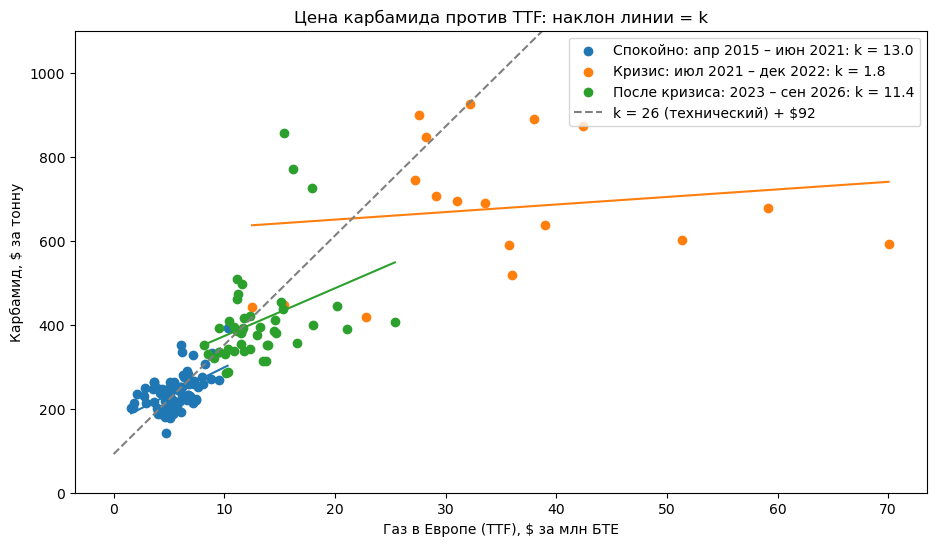

In [2]:
periods = {
    "Спокойно: апр 2015 – июн 2021": ("2015-04", "2021-06"),
    "Кризис: июл 2021 – дек 2022": ("2021-07", "2022-12"),
    "После кризиса: 2023 – сен 2026": ("2023-01", "2026-09"),
    "Трейн: апр 2015 – сен 2023": ("2015-04", "2023-09"),
}

rows = []
for name, (start, end) in periods.items():
    part = df.loc[start:end]
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    rows.append({
        "период": name,
        "месяцев": len(part),
        "k (наклон)": round(fit.slope, 1),
        "± 95%": round(1.96 * fit.stderr, 1),
        "сдвиг, $/т": round(fit.intercept),
        "R²": round(fit.rvalue ** 2, 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 6))
for name in list(periods)[:3]:
    start, end = periods[name]
    part = df.loc[start:end]
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    ax.scatter(part["gas_europe"], part["urea_price"], label=f"{name}: k = {fit.slope:.1f}")
    x = part["gas_europe"].sort_values()
    ax.plot(x, fit.intercept + fit.slope * x)
x = np.linspace(0, 40, 50)
ax.plot(x, 92 + 26 * x, color="gray", linestyle="--", label="k = 26 (технический) + $92")
ax.set_xlabel("Газ в Европе (TTF), $ за млн БТЕ")
ax.set_ylabel("Карбамид, $ за тонну")
ax.set_ylim(0, 1100)
ax.set_title("Цена карбамида против TTF: наклон линии = k")
ax.legend()
plt.show()

**Вывод:**
- По данным **k ≈ 12–13, вдвое меньше технических 26**: цена отыгрывает примерно половину подорожания газа, вторую половину «съедает» надбавка.
- Вне кризиса k устойчив: 13,0 (2015–2021) и 11,4 (2023–2026), интервалы пересекаются.
- **В кризис 2021–2022 связь почти исчезает (k ≈ 1,8):** европейские заводы остановились, цену задавали производители с дешёвым газом. Это отдельный режим.
- Для таргета k оцениваем **только на трейне**: 12,0 ± 1,5. k = 11,4 посчитан в основном по тесту, для таргета его брать нельзя.

## 2. Стационарность надбавки (ADF) для k с диаграмм

Надбавка = цена − k × газ. Тест ADF проверяет, возвращается ли она к норме: чем отрицательнее t, тем увереннее. Порог 5% — около −2,89 для k, заданного заранее (k = 26), и около −3,37 для k, оценённого по тем же данным (тест Энгла–Грейнджера).

In [3]:
from statsmodels.tsa.stattools import adfuller, coint

k_options = {
    "кризис 2021–2022": 1.8,
    "после кризиса 2023–2026": 11.4,
    "трейн целиком": 12.0,
    "спокойные 2015–2021": 13.0,
    "технический (Владислав)": 26.0,
}

rows = []
for name, k in k_options.items():
    markup = train["urea_price"] - k * train["gas_europe"]
    result = adfuller(markup, autolag="AIC")
    rows.append({
        "откуда k": name,
        "k": k,
        "ADF t": round(result[0], 2),
        "p-value": round(result[1], 3),
        "std": round(markup.std()),
        "corr с газом": round(markup.corr(train["gas_europe"]), 2),
    })
print(pd.DataFrame(rows).to_string(index=False))
print("Порог 5%:", round(result[4]["5%"], 2))

t_stat, p_value, crit = coint(train["urea_price"], train["gas_europe"])
print("Тест Энгла–Грейнджера на трейне: t =", round(t_stat, 2), " p =", round(p_value, 3))

               откуда k    k  ADF t  p-value  std  corr с газом
       кризис 2021–2022  1.8  -1.92    0.321  164          0.79
после кризиса 2023–2026 11.4  -3.34    0.013  100          0.08
          трейн целиком 12.0  -3.50    0.008  100          0.00
    спокойные 2015–2021 13.0  -3.73    0.004  101         -0.12
технический (Владислав) 26.0  -2.86    0.050  204         -0.87
Порог 5%: -2.89
Тест Энгла–Грейнджера на трейне: t = -3.52  p = 0.03


Дополнительно — все k от 0 до 30, чтобы увидеть, в каком диапазоне надбавка стационарна.

 k  ADF t  p-value  лагов  std  corr с газом
 0  -1.87    0.345      6  183          0.84
 1  -1.90    0.332      6  173          0.82
 2  -1.93    0.319      6  162          0.79
 3  -2.29    0.176      5  152          0.76
 4  -2.27    0.181      5  143          0.72
 5  -2.29    0.177      5  134          0.67
 6  -2.33    0.162      5  126          0.61
 7  -2.42    0.136      5  119          0.54
 8  -2.55    0.103      5  112          0.46
 9  -2.74    0.068      5  107          0.36
10  -2.97    0.038      5  103          0.25
11  -3.23    0.018      5  101          0.13
12  -3.50    0.008      5  100          0.00
13  -3.73    0.004      5  101         -0.12
14  -3.90    0.002      5  103         -0.24
15  -3.98    0.002      5  107         -0.36
16  -3.97    0.002      5  112         -0.45
17  -4.57    0.000      1  118         -0.54
18  -4.47    0.000      1  126         -0.61
19  -4.36    0.000      1  134         -0.67
20  -4.23    0.001      1  142         -0.71
21  -4.11 

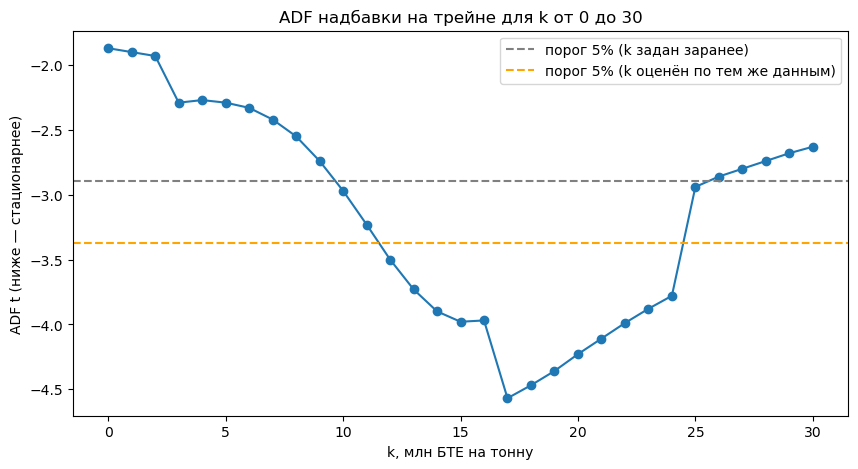

In [4]:
rows = []
for k in range(0, 31):
    markup = train["urea_price"] - k * train["gas_europe"]
    result = adfuller(markup, autolag="AIC")
    rows.append({"k": k, "ADF t": round(result[0], 2), "p-value": round(result[1], 3),
                 "лагов": result[2], "std": round(markup.std()),
                 "corr с газом": round(markup.corr(train["gas_europe"]), 2)})
table = pd.DataFrame(rows)
print(table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(table["k"], table["ADF t"], marker="o")
ax.axhline(result[4]["5%"], color="gray", linestyle="--", label="порог 5% (k задан заранее)")
ax.axhline(-3.37, color="orange", linestyle="--", label="порог 5% (k оценён по тем же данным)")
ax.set_xlabel("k, млн БТЕ на тонну")
ax.set_ylabel("ADF t (ниже — стационарнее)")
ax.set_title("ADF надбавки на трейне для k от 0 до 30")
ax.legend()
plt.show()

**Вывод:**
- При k вне кризиса (11,4 / 12,0 / 13,0) надбавка **стационарна** (t ≈ −3,3…−3,7), разброс около \$100 и почти не зависит от газа (corr ≈ 0).
- При k = 26 на трейне — **на границе** значимости (t ≈ −2,86), надбавка сильно и обратно связана с газом (corr −0,87) и уходит до −\$1230 в кризис.
- При k кризиса (1,8) надбавка блуждает вместе с газом — это почти сама цена.
- Стационарность — это диапазон примерно k = 12…24, а не одна точка; кривая неровная, потому что тест сам меняет число лагов. Поэтому окончательно k выбираем **по ошибке прогноза** (раздел 3), а не по максимуму ADF.
- Важная поправка: «надбавка при k = 26 стационарна, p = 0,010» было посчитано по всему периоду, включая тест. На трейне — только на границе.

## 3. Наивный прогноз каждый месяц

Наивный прогноз: цена через h месяцев = цена сейчас. Это бейзлайн, который модель должна обыграть. Ошибку на тесте считаем только для него: у наивного прогноза нет параметров, подсмотреть нечего.

 горизонт                        период  прогнозов  RMSE, $/т  MAE, $/т  MAPE, %
        1    трейн: апр 2015 – сен 2023        102       53.0      29.9      8.1
        1 спокойно: апр 2015 – июн 2021         75       23.4      16.3      6.9
        1   кризис: июл 2021 – дек 2022         18      112.7      83.7     12.1
        1     тест: окт 2023 – сен 2026         35       80.2      46.6      9.9
        3    трейн: апр 2015 – сен 2023        102       99.7      56.6     15.0
        3 спокойно: апр 2015 – июн 2021         75       39.5      29.8     11.9
        3   кризис: июл 2021 – дек 2022         18      218.4     171.1     28.1
        3     тест: окт 2023 – сен 2026         33      166.1     103.5     21.8


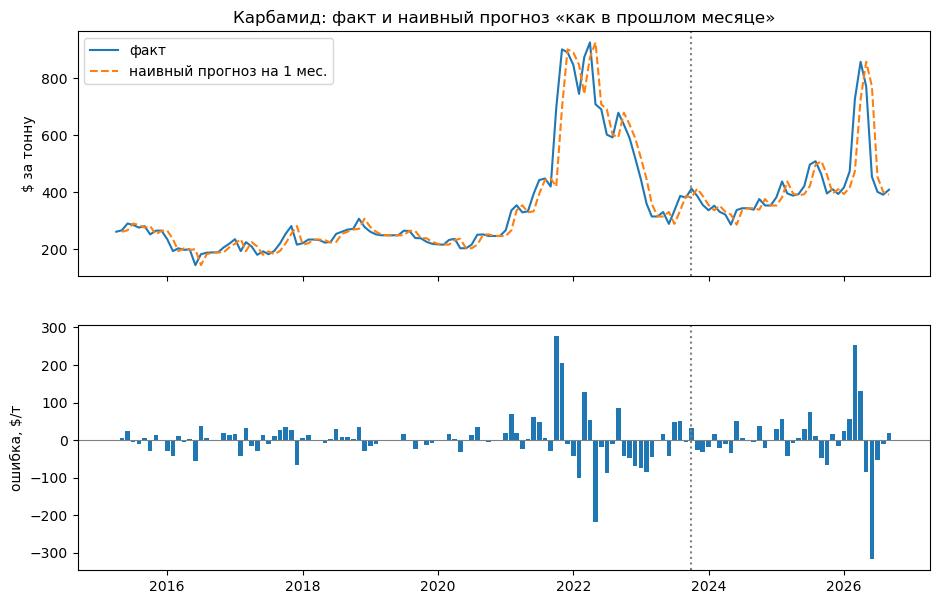

In [5]:
price = df["urea_price"]
gas = df["gas_europe"]

periods = {
    "трейн: апр 2015 – сен 2023": ("2015-04", "2023-09"),
    "спокойно: апр 2015 – июн 2021": ("2015-04", "2021-06"),
    "кризис: июл 2021 – дек 2022": ("2021-07", "2022-12"),
    "тест: окт 2023 – сен 2026": ("2023-10", "2026-09"),
}

rows = []
for h in [1, 3]:
    error = (price.shift(-h) - price).dropna()
    pct = (error.abs() / price.shift(-h)).dropna() * 100
    for name, (start, end) in periods.items():
        e = error.loc[start:end]
        rows.append({
            "горизонт": h,
            "период": name,
            "прогнозов": len(e),
            "RMSE, $/т": round(np.sqrt((e ** 2).mean()), 1),
            "MAE, $/т": round(e.abs().mean(), 1),
            "MAPE, %": round(pct.loc[start:end].mean(), 1),
        })
print(pd.DataFrame(rows).to_string(index=False))

naive = price.shift(1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(price.index, price, label="факт")
ax1.plot(naive.index, naive, linestyle="--", label="наивный прогноз на 1 мес.")
ax1.set_ylabel("$ за тонну")
ax1.legend()
error_1 = price - naive
ax2.bar(error_1.index, error_1, width=25)
ax2.axhline(0, color="gray", linewidth=0.8)
ax2.set_ylabel("ошибка, $/т")
for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp("2023-10-01"), color="gray", linestyle=":")
ax1.set_title("Карбамид: факт и наивный прогноз «как в прошлом месяце»")
plt.show()

**Вывод:** в спокойные месяцы наивный прогноз ошибается в среднем на 7% за месяц и на 12% за три месяца — обыграть его трудно. Почти вся ошибка — в шоках (осень 2021, весна 2022, март–июнь 2026): наивный прогноз всегда опаздывает на месяц. Значит, выигрыш модели возможен только на поворотах — нужны признаки, которые знают о шоке заранее.

Обыгрывают ли наивный прогноз простые модели? Сравниваем на валидации **внутри трейна** со скользящим началом прогноза. Число — MSE модели / MSE наивного прогноза; **меньше 1 — модель лучше**.

In [6]:
def rolling_forecast(h, k, origins, use_gas_change=False):
    if use_gas_change:
        base = price
        feature = gas.diff()
    else:
        base = k * gas
        feature = price - k * gas
    target = price.shift(-h) - base
    table = pd.DataFrame({"x": feature, "y": target})
    results = []
    for origin in origins:
        known = table.loc[:origin - pd.DateOffset(months=h)].dropna()
        slope, intercept = np.polyfit(known["x"], known["y"], 1)
        prediction = base.loc[origin] + intercept + slope * table.loc[origin, "x"]
        results.append((price.shift(-h).loc[origin], price.loc[origin], prediction))
    r = np.array(results)
    mse_naive = ((r[:, 0] - r[:, 1]) ** 2).mean()
    mse_model = ((r[:, 0] - r[:, 2]) ** 2).mean()
    return round(mse_model / mse_naive, 2)


windows = {
    "спокойно: янв 2018 – июн 2021": ("2018-01", "2021-06"),
    "валидация: окт 2020 – сен 2023": ("2020-10", "2023-09"),
}
rows = []
for wname, (start, end) in windows.items():
    for h in [1, 3]:
        origins = df.loc[start:end].index
        origins = origins[origins <= pd.Timestamp(end) - pd.DateOffset(months=h)]
        row = {"окно": wname, "горизонт": h}
        for k in [12, 13, 26]:
            row[f"возврат к норме, k={k}"] = rolling_forecast(h, k, origins)
        row["изменение газа"] = rolling_forecast(h, 0, origins, use_gas_change=True)
        rows.append(row)
print("Отношение MSE модели к MSE наивного прогноза (меньше 1 — модель лучше):")
print(pd.DataFrame(rows).to_string(index=False))

Отношение MSE модели к MSE наивного прогноза (меньше 1 — модель лучше):
                          окно  горизонт  возврат к норме, k=12  возврат к норме, k=13  возврат к норме, k=26  изменение газа
 спокойно: янв 2018 – июн 2021         1                   1.18                   1.19                   1.27            0.96
 спокойно: янв 2018 – июн 2021         3                   1.36                   1.37                   1.59            1.04
валидация: окт 2020 – сен 2023         1                   1.07                   1.07                   1.26            1.08
валидация: окт 2020 – сен 2023         3                   1.27                   1.25                   1.55            1.66


**Две простые модели** (линейная регрессия с одним признаком, переобучается каждый месяц на прошлом):
- **«Возврат к норме»** — признак: текущая надбавка; прогноз: k × газ сейчас + прогноз надбавки (по сути AR(1)).
- **«Изменение газа»** — признак: изменение газа за месяц; прогноз: цена сейчас + прогноз изменения цены.

**Вывод:**
- «Возврат к норме» проигрывает наивному прогнозу при любом k: норма надбавки сама сдвигается, а модель тянет прогноз к старому среднему. Стационарность надбавки ещё не значит, что её возврат к норме обыгрывает наивный прогноз на 1–3 месяца.
- Из вариантов k лучше **k = 12–13**, хуже всего k = 26 — для таргета берём k ≈ 12 (по трейну).
- «Изменение газа» немного лучше наивного в спокойные месяцы на 1 месяц, но в кризис простая модель ломается.

## 4. Трейн/тест, скользящие окна, предобработка после деления

Общий код проверки моделей вынесен в src/models/backtest.py, чтобы все модели команды сравнивались одинаково:
- split_train_test — деление только по времени (тест с октября 2023);
- rolling_backtest — прогноз со скользящим началом: на каждом месяце модель учится только на строках, ответ для которых уже известен (origin − h); окно обучения — **расширяющееся** (вся история) или **скользящее** (последние N месяцев);
- предобработка (масштабирование) делается **внутри** модели и обучается только на известных строках — сначала делим, потом предобрабатываем.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.models.backtest import make_table, split_train_test, rolling_backtest, score

h = 1
table = make_table(df, h)
train_t, test_t = split_train_test(table)
print("Трейн:", train_t.index.min().date(), "–", train_t.index.max().date(), len(train_t), "мес.")
print("Тест: ", test_t.index.min().date(), "–", test_t.index.max().date(), len(test_t), "мес.")


def gas_change_model(known, now):
    slope, intercept = np.polyfit(known["gas_change"], known["y"] - known["price"], 1)
    return now["price"].iloc[0] + intercept + slope * now["gas_change"].iloc[0]


features = ["gas_change", "gas_change_lag1", "price_change"]


def ridge_model(known, now):
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(known[features], known["y"] - known["price"])
    return now["price"].iloc[0] + model.predict(now[features])[0]


valid_origins = train_t.loc["2020-10":].index
valid_origins = valid_origins[valid_origins <= train_t.index.max() - pd.DateOffset(months=h)]

for name, model in [("изменение газа", gas_change_model), ("ridge, 3 признака", ridge_model)]:
    for window in [None, 60, 36]:
        results = rolling_backtest(table, h, model, valid_origins, window=window)
        label = "расширяющееся" if window is None else f"скользящее {window} мес."
        print(f"\n{name} | окно: {label}")
        print(score(results).to_string())

Трейн: 2015-04-01 – 2023-09-01 102 мес.
Тест:  2023-10-01 – 2026-09-01 36 мес.

изменение газа | окно: расширяющееся
             прогнозов  RMSE модели  RMSE наивного  MSE модель / наивный
все               35.0         89.2           85.7                  1.08
без кризиса       17.0         31.8           41.0                  0.60
кризис            18.0        120.5          112.7                  1.14

изменение газа | окно: скользящее 60 мес.
             прогнозов  RMSE модели  RMSE наивного  MSE модель / наивный
все               35.0         89.9           85.7                  1.10
без кризиса       17.0         31.6           41.0                  0.59
кризис            18.0        121.6          112.7                  1.16

изменение газа | окно: скользящее 36 мес.
             прогнозов  RMSE модели  RMSE наивного  MSE модель / наивный
все               35.0         91.2           85.7                  1.13
без кризиса       17.0         31.4           41.0                 

**Вывод:**
- **Вне кризиса** модели на ценах заметно лучше наивного прогноза (MSE меньше на 40–45%), но таких месяцев в окне валидации всего 17 — вывод предварительный.
- **Весь проигрыш — в кризисе 2021–2022**: модели ошибаются сильнее наивного и тянут общий результат выше 1. Нужен признак режима и признаки шоков (проливы, экспорт Китая, GSCPI).
- **Скользящие окна не помогают:** расширяющееся окно не хуже, а в кризис лучше — короткое окно «забывает» прошлые шоки. Основной вариант — расширяющееся окно, скользящие 60 и 36 месяцев — проверка устойчивости.
- Тест не трогаем, пока не выбрана финальная модель.

## 5. Можно ли удлинить ряд газа до 2015 года?

В Pink Sheet газ Европы есть с 1960 года, но **до апреля 2015 это другой показатель**: цена импорта на границе — в основном долгосрочные контракты, привязанные к нефти (2010 – март 2015 — плюс спотовая составляющая с Великобританией). Проверяем, похожа ли связь с карбамидом до и после.

In [8]:
full = pd.read_parquet("../data/processed/prices_monthly.parquet")
rows = []
for name, (start, end) in {
    "2000–2009 (контракты)": ("2000-01", "2009-12"),
    "2010 – мар 2015 (контракты + спот)": ("2010-01", "2015-03"),
    "апр 2015 – сен 2023 (TTF, трейн)": ("2015-04", "2023-09"),
}.items():
    part = full.loc[start:end]
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    gas_change = np.log(part["gas_europe"]).diff()
    urea_next = np.log(part["urea_price"]).diff().shift(-1)
    rows.append({
        "период": name,
        "месяцев": len(part),
        "k (наклон)": round(fit.slope, 1),
        "± 95%": round(1.96 * fit.stderr, 1),
        "изменение газа → карбамид через месяц": round(gas_change.corr(urea_next), 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

                            период  месяцев  k (наклон)  ± 95%  изменение газа → карбамид через месяц
             2000–2009 (контракты)      120        35.6    4.0                                   0.04
2010 – мар 2015 (контракты + спот)       63        27.9   11.2                                   0.05
  апр 2015 – сен 2023 (TTF, трейн)      102        12.0    1.5                                   0.38


**Вывод:** до 2015 года наклон в уровнях больше (k ≈ 28–36 против 12 на трейне с TTF), но это скорее общий нефтяной цикл 2000-х, а главное — **изменение газа до 2015 года не помогает прогнозировать карбамид** (корреляция около 0,05), тогда как на TTF-периоде — помогает (около 0,38). Склейка двух рядов ломает таргет: одного k на весь период нет. Поэтому основная модель — с апреля 2015; длинный ряд можно использовать только как проверку устойчивости с флагом gas_oil_indexed и разными k. Настоящая история TTF до 2015 года есть в платных источниках (ICE Endex, Bloomberg, Argus).